# 02 — Baseline: Seasonal Naive (sNaive)
**Task:** at time *t*, for every oblast, predict **P(an alert starts in (t, t+h])**, h ∈ {15, 30, 60} min.

**Seasonal naive** = "the future looks like the same time window in the previous season":
- **sNaive-1d:** prediction = did an alert start in the same window *yesterday*?
- **sNaive-7d:** … in the same window *one week ago*?
- **sNaive-mean (probabilistic):** share of the last *K* days/weeks where an alert started in that window.

For reference we also include **climatology** (P(start) by oblast × hour, from train).

**No leakage:** the lagged window (t−L, t−L+h] ends at t−L+h ≤ t because h ≤ 60 min < L = 1 day.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, precision_recall_curve

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (13, 4)
DATA_DIR = Path("data")

starts = pd.read_parquet(DATA_DIR / "starts_5min.parquet")
state  = pd.read_parquet(DATA_DIR / "state_5min.parquet")
split  = {k: pd.Timestamp(v) for k, v in json.loads((DATA_DIR / "split.json").read_text()).items()}
STEP = starts.index[1] - starts.index[0]
DAY  = int(pd.Timedelta("1D") / STEP)
HORIZONS = {"15min": 3, "30min": 6, "60min": 12}
oblasts = list(starts.columns)
print(starts.shape, STEP, split)

(471331, 24) 0 days 00:05:00 {'val_start': Timestamp('2026-07-09 00:00:00+0300', tz='UTC+03:00'), 'test_start': Timestamp('2026-08-08 00:00:00+0300', tz='UTC+03:00')}


## 1. Target: alert start within (t, t+h]
Computed with cumulative sums: `y[t] = cs[t+k] − cs[t]` = number of starts in steps t+1 … t+k.

In [2]:
def future_starts(S: pd.DataFrame, k: int) -> pd.DataFrame:
    cs = np.vstack([np.zeros((1, S.shape[1])), np.cumsum(S.values, axis=0)])   # cs[i] = starts in steps < i
    n = len(S)
    y = np.full(S.shape, np.nan)
    y[: n - k] = cs[k + 1 : n + 1] - cs[1 : n - k + 1]                          # steps t+1 … t+k
    return pd.DataFrame((y > 0).astype(float), index=S.index, columns=S.columns).where(~np.isnan(y))

Y = {h: future_starts(starts, k) for h, k in HORIZONS.items()}
Y["30min"].loc[split["test_start"]:].mean().sort_values(ascending=False).round(3).head()

Mykolaivska oblast     0.181
Odeska oblast          0.176
Khersonska oblast      0.129
Poltavska oblast       0.115
Chernihivska oblast    0.106
dtype: float64

## 2. Oblast groups
Frontline oblasts are under alert most of the time, which makes "a new alert starts" a different problem there.
Group defined **on train data only**: share of time on alert > 25 % → frontline.

In [3]:
train_state = state.loc[split["val_start"] - pd.Timedelta(days=365): split["val_start"]]
share = train_state.mean().sort_values(ascending=False)
FRONT = share[share > 0.25].index.tolist()
REAR  = [o for o in oblasts if o not in FRONT]
print("frontline:", FRONT)
print("rear     :", REAR)

frontline: ['Dnipropetrovska oblast', 'Donetska oblast', 'Sumska oblast', 'Kharkivska oblast', 'Chernihivska oblast', 'Zaporizka oblast', 'Poltavska oblast', 'Khersonska oblast']
rear     : ['Cherkaska oblast', 'Chernivetska oblast', 'Ivano-Frankivska oblast', 'Khmelnytska oblast', 'Kirovohradska oblast', 'Kyiv City', 'Kyivska oblast', 'Lvivska oblast', 'Mykolaivska oblast', 'Odeska oblast', 'Rivnenska oblast', 'Ternopilska oblast', 'Vinnytska oblast', 'Volynska oblast', 'Zakarpatska oblast', 'Zhytomyrska oblast']


## 3. Baseline forecasts

In [4]:
def snaive(Yh: pd.DataFrame, lag_days: int) -> pd.DataFrame:
    return Yh.shift(lag_days * DAY)

def snaive_mean(Yh: pd.DataFrame, lag_days: int, K: int) -> pd.DataFrame:
    return sum(Yh.shift(m * lag_days * DAY) for m in range(1, K + 1)) / K

def climatology(Yh: pd.DataFrame, train_end, days=365) -> pd.DataFrame:
    tr = Yh.loc[train_end - pd.Timedelta(days=days): train_end - pd.Timedelta("1h")]
    prof = tr.groupby(tr.index.hour).mean()                     # hour × oblast, train only
    return pd.DataFrame(prof.loc[Yh.index.hour].values, index=Yh.index, columns=Yh.columns)

def make_forecasts(Yh, train_end):
    return {
        "sNaive-1d":        snaive(Yh, 1),
        "sNaive-7d":        snaive(Yh, 7),
        "sNaive-mean 7×1d": snaive_mean(Yh, 1, 7),
        "sNaive-mean 4×7d": snaive_mean(Yh, 7, 4),
        "Climatology":      climatology(Yh, train_end),
    }

# Leakage sanity check: the lag-1d window must end before t
for h, k in HORIZONS.items():
    assert k < DAY, "horizon must be shorter than the seasonal lag"
print("ok")

ok


## 4. Evaluation

In [5]:
def evaluate(F: dict, Yh: pd.DataFrame, start, end, cols) -> pd.DataFrame:
    rows = []
    y = Yh.loc[start:end, cols].values.ravel()
    for name, P in F.items():
        p = P.loc[start:end, cols].values.ravel()
        m = ~np.isnan(y) & ~np.isnan(p)
        yy, pp = y[m], np.clip(p[m], 0, 1)
        rows.append({"model": name,
                     "Brier": brier_score_loss(yy, pp),
                     "PR-AUC": average_precision_score(yy, pp),
                     "ROC-AUC": roc_auc_score(yy, pp),
                     "base rate": yy.mean()})
    return pd.DataFrame(rows).set_index("model")

results = []
for h in HORIZONS:
    F = make_forecasts(Y[h], split["val_start"])
    for period, (a, b) in {"val": (split["val_start"], split["test_start"]),
                           "test": (split["test_start"], None)}.items():
        for grp, cols in {"all": oblasts, "rear": REAR, "frontline": FRONT}.items():
            r = evaluate(F, Y[h], a, b, cols)
            r["horizon"], r["period"], r["group"] = h, period, grp
            results.append(r.reset_index())
res = pd.concat(results)
res.query("period == 'test' and group == 'rear'").round(4)

,model,Brier,PR-AUC,ROC-AUC,base rate,horizon,period,group
0,sNaive-1d,0.0455,0.0291,0.5291,0.0246,15min,test,rear
1,sNaive-7d,0.0468,0.0273,0.5213,0.0246,15min,test,rear
2,sNaive-mean 7×1d,0.0263,0.0401,0.6070,0.0246,15min,test,rear
3,sNaive-mean 4×7d,0.0290,0.0340,0.5695,0.0246,15min,test,rear
4,Climatology,0.0235,0.0730,0.7985,0.0246,15min,test,rear
0,sNaive-1d,0.0838,0.0636,0.5527,0.0489,30min,test,rear
1,sNaive-7d,0.0870,0.0585,0.5410,0.0489,30min,test,rear
2,sNaive-mean 7×1d,0.0491,0.0945,0.6636,0.0489,30min,test,rear
3,sNaive-mean 4×7d,0.0540,0.0811,0.6229,0.0489,30min,test,rear
4,Climatology,0.0446,0.1445,0.8050,0.0489,30min,test,rear


In [6]:
# Summary: PR-AUC on test, horizon × model, per group
for grp in ["rear", "frontline", "all"]:
    t = res.query("period == 'test' and group == @grp").pivot(index="model", columns="horizon", values="PR-AUC")
    print(f"\n=== PR-AUC, test, {grp} ===")
    print(t[list(HORIZONS)].round(3))


=== PR-AUC, test, rear ===
horizon           15min  30min  60min
model                                
Climatology       0.073  0.145  0.274
sNaive-1d         0.029  0.064  0.141
sNaive-7d         0.027  0.059  0.128
sNaive-mean 4×7d  0.034  0.081  0.189
sNaive-mean 7×1d  0.040  0.094  0.210

=== PR-AUC, test, frontline ===
horizon           15min  30min  60min
model                                
Climatology       0.059  0.115  0.218
sNaive-1d         0.045  0.093  0.186
sNaive-7d         0.043  0.087  0.172
sNaive-mean 4×7d  0.046  0.096  0.195
sNaive-mean 7×1d  0.049  0.107  0.217

=== PR-AUC, test, all ===
horizon           15min  30min  60min
model                                
Climatology       0.060  0.118  0.223
sNaive-1d         0.034  0.073  0.155
sNaive-7d         0.032  0.068  0.141
sNaive-mean 4×7d  0.038  0.085  0.189
sNaive-mean 7×1d  0.043  0.098  0.211


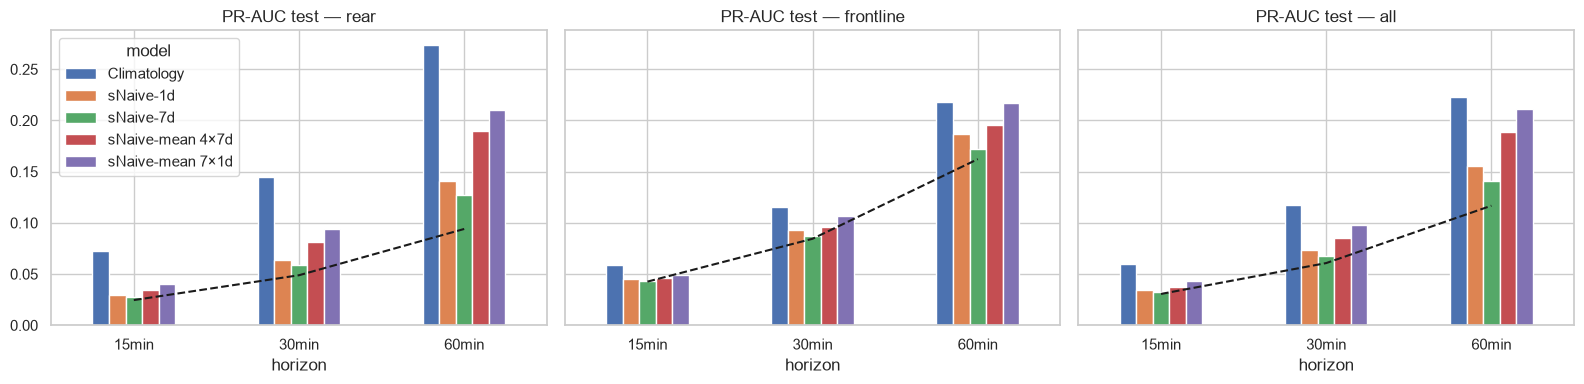

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for a, grp in zip(ax, ["rear", "frontline", "all"]):
    t = res.query("period == 'test' and group == @grp").pivot(index="horizon", columns="model", values="PR-AUC").loc[list(HORIZONS)]
    t.plot(kind="bar", ax=a, legend=(grp == "rear"), rot=0, title=f"PR-AUC test — {grp}")
    base = res.query("period == 'test' and group == @grp").groupby("horizon")["base rate"].first().loc[list(HORIZONS)]
    a.plot(range(3), base.values, "k--", label="random (base rate)")
plt.tight_layout(); plt.show()

## 5. Precision–recall curves (h = 30 min, test, rear oblasts)

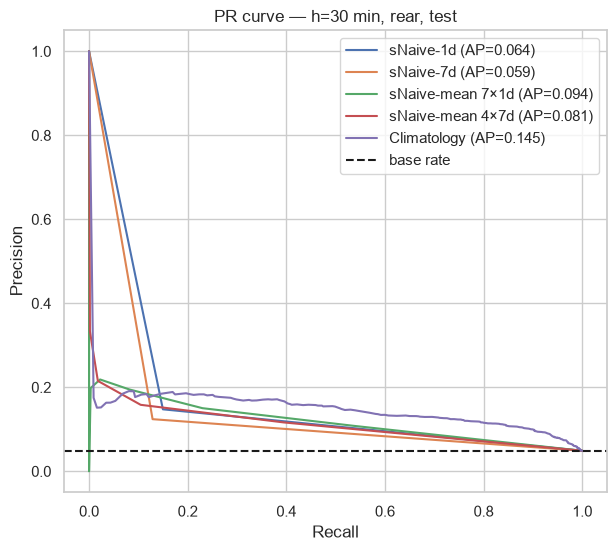

In [8]:
h = "30min"
F = make_forecasts(Y[h], split["val_start"])
y = Y[h].loc[split["test_start"]:, REAR].values.ravel()
plt.figure(figsize=(7, 6))
for name, P in F.items():
    p = P.loc[split["test_start"]:, REAR].values.ravel()
    m = ~np.isnan(y) & ~np.isnan(p)
    pr, rc, _ = precision_recall_curve(y[m], p[m])
    plt.plot(rc, pr, label=f"{name} (AP={average_precision_score(y[m], p[m]):.3f})")
plt.axhline(np.nanmean(y), ls="--", c="k", label="base rate")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.legend(); plt.title("PR curve — h=30 min, rear, test")
plt.show()

## 6. Per-oblast results (h = 30 min, test, best sNaive)

In [9]:
best = res.query("period=='val' and group=='rear' and horizon=='30min' and model.str.startswith('sNaive')", engine="python") \
          .sort_values("PR-AUC").iloc[-1]["model"]
print("best sNaive on validation:", best)

per = []
for o in oblasts:
    yy = Y[h].loc[split["test_start"]:, o]; pp = F[best].loc[split["test_start"]:, o]
    m = yy.notna() & pp.notna()
    if yy[m].sum() < 5: continue
    per.append({"oblast": o, "group": "front" if o in FRONT else "rear",
                "PR-AUC": average_precision_score(yy[m], pp[m]),
                "base rate": yy[m].mean(), "n starts": int(starts.loc[split['test_start']:, o].sum())})
per = pd.DataFrame(per).set_index("oblast").sort_values("PR-AUC")
per["lift over random"] = per["PR-AUC"] / per["base rate"]
per.round(3)

best sNaive on validation: sNaive-mean 7×1d


,group,PR-AUC,base rate,n starts,lift over random
oblast,,,,,
Chernivetska oblast,rear,0.003,0.003,5,1.000
Ternopilska oblast,rear,0.005,0.005,7,1.000
Volynska oblast,rear,0.008,0.005,7,1.571
Rivnenska oblast,rear,0.012,0.012,18,0.984
Khmelnytska oblast,rear,0.014,0.014,20,0.992
Dnipropetrovska oblast,front,0.028,0.018,27,1.565
Vinnytska oblast,rear,0.038,0.034,50,1.094
Zhytomyrska oblast,rear,0.041,0.041,60,0.996
Kyiv City,rear,0.066,0.066,97,1.012


## 7. Example: Kyiv City, a week in the test period

/Users/alona/Documents/KSE/agentic/.venv/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:999: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


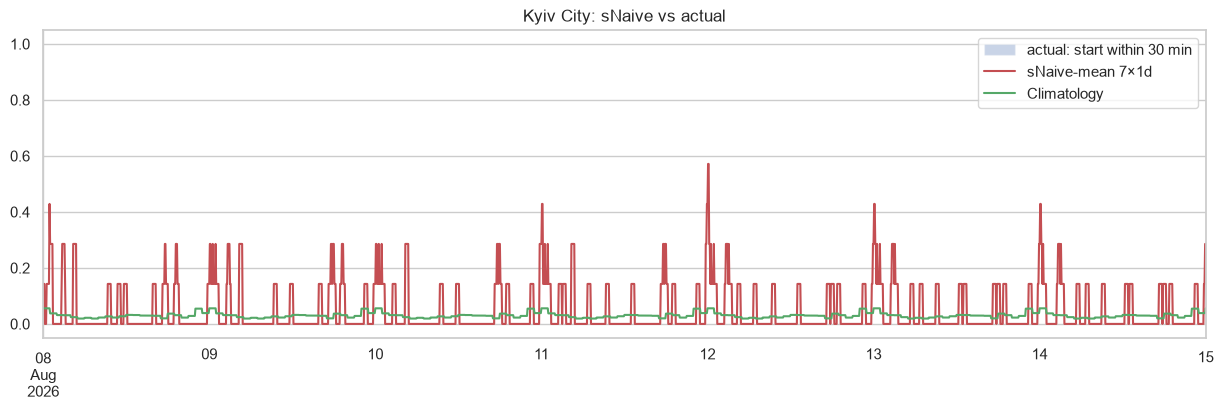

In [10]:
o = "Kyiv City"
w0 = split["test_start"]; w1 = w0 + pd.Timedelta(days=7)
fig, ax = plt.subplots(figsize=(15, 4))
ax.fill_between(Y[h].loc[w0:w1].index, Y[h].loc[w0:w1, o], step="post", alpha=.3, label="actual: start within 30 min")
F[best].loc[w0:w1, o].plot(ax=ax, label=best, c="C3")
F["Climatology"].loc[w0:w1, o].plot(ax=ax, label="Climatology", c="C2")
ax.legend(); ax.set_title(f"{o}: sNaive vs actual")
plt.show()

In [11]:
res.to_csv(DATA_DIR / "results_02_snaive.csv", index=False)
print("saved")

saved


## Conclusions (fill in after running)
- Best sNaive variant: …
- sNaive vs climatology: …
- Rear vs frontline: …
- **This is the bar** for the next models (own-history logistic regression, LightGBM with spatial features).